# CODE 4.3: Score the Photos with YOLO

> **Goal:** give every validation and test photo one score from each of the 12 YOLO models of notebook 4.2, the same kind of score that PatchCore gave in notebook 4.1, and save the scores for step 5.
>
> - **Input:** the trained models `models/yolo/split_1_k5/weights/last.pt` and so on (notebook 4.2), the crops and labels (notebooks 3.1 and 3.2), the split files (notebook 1.3), and for a first comparison the PatchCore scores `results/patchcore/split_1_scores.csv` and so on (notebook 4.1)
> - **Output:**
>   - `results/yolo/split_1_scores.csv` (and the same for splits 2 and 3): one row per validation and test photo and per k, with its score
>   - `results/yolo/split_1_boxes.csv` (and 2, 3): the boxes YOLO found in these photos, to draw them in step 5 and the demo
>
> Like notebook 4.1, this notebook only **looks at the validation photos**. The test scores are saved but not looked at: step 5 compares both models on the test photos, once.

### How YOLO Gives a Photo a Score

> YOLO's answer for a photo is a list of boxes, each with a **confidence** from 0 to 1: how sure YOLO is that there is a defect inside. To compare YOLO with PatchCore, every photo needs **one number**, like PatchCore's anomaly score.
>
> We use the **highest confidence of all boxes** in the photo. If YOLO is very sure about at least one defect somewhere, the photo gets a high score. If YOLO only finds places it is very unsure about, the score is tiny. This is the same idea as PatchCore, whose score is the distance of its most unusual patch.
>
> YOLO26 proposes up to 300 places in every photo, each with a confidence. Usually, only boxes above a lower limit are kept (Ultralytics uses 0.001 when it checks a model). On good gum, all proposals are often below that limit. With a limit, many photos would get no box at all and would all share the score 0, and photos with the same score cannot be put in order: neither the AUROC nor the PASS/REJECT limit of step 5 could tell them apart. So we use **no lower limit** (`MIN_CONFIDENCE = 0`): every photo gets its own score, even if it is tiny. Step 1 counts how many photos would have scored 0 with the usual limit.
>
> Which score is high enough to REJECT a photo is decided in step 5, from the validation photos, in the same way for both models.

### Words Used in This Notebook

> - **Prediction:** YOLO's answer for a photo it has not learned from: boxes with confidences.
> - **Confidence:** how sure YOLO is about one box, from 0 to 1.
> - **Score of a photo:** the highest confidence of all places YOLO proposes in it.
> - **Small numbers:** Python writes very small numbers like `2.5e-05`, which means 0.000025 (`e-05`: move the point 5 places to the left). Without a lower limit, many scores are this small.
> - **True box:** a box from the labels of notebook 3.2, drawn around a real defect.
> - **AUROC:** the chance that a random defect photo gets a higher score than a random normal photo. 1.0 means always, 0.5 means guessing (see README).

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths. `logging`: sets how much Ultralytics prints.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures. `Rectangle` draws boxes on a picture.
> - `PIL` (Pillow): opens the crops.
> - `roc_auc_score` (scikit-learn): computes the AUROC.
> - `torch`: PyTorch, to check the GPU.
> - `YOLO` (Ultralytics): loads the trained models and lets them predict. `LOGGER` is the part of Ultralytics that prints messages.
> - `tqdm`: shows a progress bar.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.metrics import roc_auc_score
import torch
from ultralytics import YOLO
from ultralytics.utils import LOGGER
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `SPLITS_DIR`: our split files (notebook 1.3).
> - `CROP_DIR`, `CROP_TABLE_FILE`: the crops, their labels and their table (notebooks 3.1 and 3.2).
> - `YOLO_DIR`: the trained YOLO models (notebook 4.2).
> - `PATCHCORE_DIR`: the PatchCore scores (notebook 4.1), only used for a first comparison on the validation photos.
> - `RESULTS_DIR`: where the YOLO scores and boxes are saved. These files are small, and step 5 reads them.
>
> If notebook 4.2 has not finished, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
CROP_TABLE_FILE = os.path.join(CROP_DIR, "crop_boxes.csv")
YOLO_DIR = os.path.join(ROOT_DIR, "models", "yolo")
PATCHCORE_DIR = os.path.join(ROOT_DIR, "results", "patchcore")
RESULTS_DIR = os.path.join(ROOT_DIR, "results", "yolo")

if not os.path.exists(os.path.join(YOLO_DIR, "split_3_k40", "weights", "last.pt")):
    raise FileNotFoundError("models/yolo/split_3_k40/weights/last.pt not found. Run notebook 4.2 until all models are trained.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLITS`, `K_VALUES`: the 12 models of notebook 4.2 (the demo model is not part of the comparison).
> - `IMAGE_SIZE`: 928 pixels, the same size as in training, so the crops are not made smaller.
> - `MIN_CONFIDENCE`: 0, no lower limit: keep boxes however unsure YOLO is (explained above).
> - `MAX_BOXES`: keep at most the 20 most confident boxes per photo. The score only needs the first one; the others are saved to draw them later. Without a lower limit, many of these boxes have a tiny confidence.
> - `EXAMPLE_SPLIT`, `EXAMPLE_PHOTOS`: Step 3 shows boxes of 5 photos of split 1.

In [3]:
SPLITS = [1, 2, 3]
K_VALUES = [5, 10, 20, 40]
IMAGE_SIZE = 928
MIN_CONFIDENCE = 0.0
MAX_BOXES = 20
EXAMPLE_SPLIT = 1
EXAMPLE_PHOTOS = 5

#### GPU and Messages

> - `DEVICE`: the first GPU (number `0`) if PyTorch can use it, otherwise the CPU (slower, but fine for predictions).
> - As in notebook 4.2, Ultralytics only prints warnings and errors.

In [4]:
DEVICE = 0 if torch.cuda.is_available() else "cpu"
LOGGER.setLevel(logging.WARNING)

print("Predicting on:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Predicting on: NVIDIA GeForce RTX 5070 Laptop GPU


## Functions

### Paths and Names

> - `full_path()` turns a path from a table, written with `/`, into a real path on this computer (as in the earlier notebooks).
> - `short_name()` shortens a path for titles: `images/Anomaly/042.png` becomes `Anomaly/042`.

In [5]:
def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))


def short_name(rel_path):
    return os.path.splitext("/".join(rel_path.split("/")[-2:]))[0]

### True Boxes of a Crop

> `true_boxes()` reads the label file of a crop (notebook 3.2): `images/Anomaly/042.png` has its boxes in `labels/Anomaly/042.txt`. Each line is `class x_centre y_centre width height`, as shares of the crop size. They are turned into pixel corners (left, top, right, bottom), to draw them. A normal crop has no boxes.

In [6]:
def true_boxes(crop_image, crop_size):
    parts = crop_image.split("/")[1:]
    label_file = os.path.join(CROP_DIR, "labels", *parts[:-1], os.path.splitext(parts[-1])[0] + ".txt")
    corners = []
    with open(label_file) as f:
        for line in f:
            if line.strip():
                _, x_centre, y_centre, width, height = (float(value) for value in line.split())
                corners.append(((x_centre - width / 2) * crop_size[0], (y_centre - height / 2) * crop_size[1],
                                (x_centre + width / 2) * crop_size[0], (y_centre + height / 2) * crop_size[1]))
    return corners

### Predict the Photos

> `predict_photos()` lets one YOLO model look at the given crops, one by one:
>
> - `model.predict()` returns YOLO's boxes for a crop, with the settings above. `verbose=False` keeps it from printing a line per photo.
> - `boxes.conf` holds the confidence of each box, `boxes.xyxy` its corners in crop pixels (left, top, right, bottom). Ultralytics sorts the boxes from the most to the least confident.
> - The score of the photo is the highest confidence. Without a lower limit, every photo should get boxes. If a photo still got none, its score would be 0; the preview below counts such photos.
>
> It returns the scores, the corners of the most confident box of every photo (empty when there is none), and a table of all kept boxes.

In [7]:
def predict_photos(model, rel_paths, desc):
    scores, best_boxes, box_rows = [], [], []
    for rel_path in tqdm(rel_paths, desc=desc):
        result = model.predict(full_path(CROP_DIR, rel_path), imgsz=IMAGE_SIZE, conf=MIN_CONFIDENCE,
                               max_det=MAX_BOXES, device=DEVICE, verbose=False)[0]
        confidences = result.boxes.conf.cpu().numpy()
        corners = result.boxes.xyxy.cpu().numpy()
        order = np.argsort(-confidences)
        confidences, corners = confidences[order], corners[order]
        scores.append(float(confidences[0]) if len(confidences) else 0.0)
        best_boxes.append(np.round(corners[0].astype(float), 1) if len(confidences) else np.full(4, np.nan))
        for confidence, (left, top, right, bottom) in zip(confidences, corners):
            box_rows.append({"crop_image": rel_path, "confidence": float(confidence),
                             "left": round(float(left), 1), "top": round(float(top), 1),
                             "right": round(float(right), 1), "bottom": round(float(bottom), 1)})
    return np.array(scores), np.array(best_boxes), pd.DataFrame(box_rows)

### Draw a Crop with Boxes

> `show_boxes()` draws a crop with its true boxes (white, dashed) and the most confident YOLO box (red), with its confidence written above it. If YOLO found no box, only the true boxes are drawn.

In [8]:
def show_boxes(ax, crop, truth, best_box, score):
    ax.imshow(crop)
    for left, top, right, bottom in truth:
        ax.add_patch(Rectangle((left, top), right - left, bottom - top, fill=False, edgecolor="white",
                               linewidth=1.5, linestyle="--"))
    if not np.isnan(best_box).any():
        left, top, right, bottom = best_box
        ax.add_patch(Rectangle((left, top), right - left, bottom - top, fill=False, edgecolor="red", linewidth=2))
        ax.text(left, top - 8, f"{score:.3g}", color="red", fontsize=10, fontweight="bold")
    ax.axis("off")

## Load Data

### Load the Crop Table, the Splits and the Models

> - `crops`: one row per photo, with the path of its crop (notebook 3.1). `CROP_SIZE`: the size of every crop.
> - `splits`: the 3 split files, each with the crop paths added.
> - `model_files`: the `last.pt` of the 12 models, always the model after the last epoch (notebook 4.2).

In [9]:
crops = pd.read_csv(CROP_TABLE_FILE)
splits = {}
for s in SPLITS:
    split = pd.read_csv(os.path.join(SPLITS_DIR, f"split_{s}.csv")).fillna({"mask": "", "defect_types": ""})
    splits[s] = split.merge(crops[["image", "crop_image"]], on="image")
CROP_SIZE = Image.open(full_path(CROP_DIR, crops["crop_image"].iloc[0])).size

model_files = {(s, k): os.path.join(YOLO_DIR, f"split_{s}_k{k}", "weights", "last.pt") for s in SPLITS for k in K_VALUES}
print(f"Crops: {len(crops)}, size {CROP_SIZE[0]} x {CROP_SIZE[1]} pixels")
print(f"Models found: {sum(os.path.exists(path) for path in model_files.values())} of {len(model_files)}")

Crops: 603, size 928 x 608 pixels
Models found: 12 of 12


## Step 1: Score the Validation and Test Photos

### Predict with All 12 Models

> For each split, the photos to score are its 60 validation and 150 test photos, validation first, each sorted by name (the same order as in notebook 4.1). Each of the 4 models of the split (k = 5, 10, 20, 40) predicts all of them.
>
> - `scores[s]`: one row per photo and per k: `image`, `crop_image`, `part`, `is_defect`, `defect_types`, `k`, `score`, and the corners of the most confident box (`best_left`, `best_top`, `best_right`, `best_bottom`; empty when there is no box).
> - `boxes[s]`: every kept box: `k`, `crop_image`, `confidence` and its corners.

In [10]:
scores, boxes = {}, {}
for s in SPLITS:
    scored = splits[s][splits[s]["split"].isin(["val", "test"])].sort_values(["split", "image"], ascending=[False, True])
    score_tables, box_tables = [], []
    for k in K_VALUES:
        model = YOLO(model_files[(s, k)])
        photo_scores, best_boxes, box_table = predict_photos(model, scored["crop_image"].tolist(),
                                                             desc=f"Split {s}, k = {k}: predicting")
        table = pd.DataFrame({"image": scored["image"].to_numpy(), "crop_image": scored["crop_image"].to_numpy(),
                              "part": scored["split"].to_numpy(), "is_defect": scored["is_defect"].to_numpy(),
                              "defect_types": scored["defect_types"].to_numpy(), "k": k, "score": photo_scores,
                              "best_left": best_boxes[:, 0], "best_top": best_boxes[:, 1],
                              "best_right": best_boxes[:, 2], "best_bottom": best_boxes[:, 3]})
        score_tables.append(table)
        box_table.insert(0, "k", k)
        box_tables.append(box_table)
    scores[s] = pd.concat(score_tables, ignore_index=True)
    boxes[s] = pd.concat(box_tables, ignore_index=True)
    print(f"Split {s}: {len(scored)} photos x {len(K_VALUES)} models = {len(scores[s])} scores, {len(boxes[s])} boxes kept")

Split 1, k = 40: predicting: 100%|██████████| 210/210 [00:08<00:00, 24.37it/s]


Split 1: 210 photos x 4 models = 840 scores, 16800 boxes kept


Split 2, k = 40: predicting: 100%|██████████| 210/210 [00:06<00:00, 33.38it/s]


Split 2: 210 photos x 4 models = 840 scores, 16800 boxes kept


Split 3, k = 40: predicting: 100%|██████████| 210/210 [00:07<00:00, 29.36it/s]

Split 3: 210 photos x 4 models = 840 scores, 16800 boxes kept


### Preview Before Saving

> What will be saved, one of each file per split:
>
> - `results/yolo/split_1_scores.csv`: the table `scores` of the split.
> - `results/yolo/split_1_boxes.csv`: the table `boxes` of the split.
>
> Below: the size of every table, and for the validation photos (counted over the 4 models; the test photos are not looked at) how many got no box at all, and how many have a score below 0.001, so would have scored 0 with Ultralytics' usual lower limit. Then the first validation rows of split 1 for k = 5.

In [11]:
for s in SPLITS:
    val_scores = scores[s][scores[s]["part"] == "val"]
    print(f"Split {s}: scores {scores[s].shape[0]} rows x {scores[s].shape[1]} columns | "
          f"boxes {boxes[s].shape[0]} rows x {boxes[s].shape[1]} columns | "
          f"validation photos without any box: {(val_scores['score'] == 0).sum()} of {len(val_scores)}, "
          f"with a score below 0.001: {(val_scores['score'] < 0.001).sum()} of {len(val_scores)}")
first_rows = scores[EXAMPLE_SPLIT]
first_rows[(first_rows["part"] == "val") & (first_rows["k"] == K_VALUES[0])].head()

Split 1: scores 840 rows x 11 columns | boxes 16800 rows x 7 columns | validation photos without any box: 0 of 240, with a score below 0.001: 146 of 240
Split 2: scores 840 rows x 11 columns | boxes 16800 rows x 7 columns | validation photos without any box: 0 of 240, with a score below 0.001: 160 of 240
Split 3: scores 840 rows x 11 columns | boxes 16800 rows x 7 columns | validation photos without any box: 0 of 240, with a score below 0.001: 159 of 240


,image,crop_image,part,is_defect,defect_types,k,score,best_left,best_top,best_right,best_bottom
0,chewinggum/Data/Images/Anomaly/005.JPG,images/Anomaly/005.png,val,True,corner missing,5,0.923228,389.9,82.0,579.0,227.7
1,chewinggum/Data/Images/Anomaly/015.JPG,images/Anomaly/015.png,val,True,"chunk of gum missing,small cracks",5,0.965912,113.9,142.4,428.6,347.7
2,chewinggum/Data/Images/Anomaly/023.JPG,images/Anomaly/023.png,val,True,chunk of gum missing,5,0.001750,319.0,408.1,664.7,608.0
3,chewinggum/Data/Images/Anomaly/038.JPG,images/Anomaly/038.png,val,True,"corner missing,small cracks",5,0.788322,80.4,70.9,139.7,192.9
4,chewinggum/Data/Images/Anomaly/043.JPG,images/Anomaly/043.png,val,True,chunk of gum missing,5,0.955717,471.4,176.2,775.6,332.9


> **What we see:**
>
> - Every photo got its own score: no validation photo is without a box, and every split kept 16800 boxes, 20 for each of its 840 scores.
> - 146, 160 and 159 of the 240 validation scores (split 1, 2, 3) are below 0.001. With Ultralytics' usual lower limit, all these photos would have shared the score 0.
> - In the first rows (split 1, k = 5), four defect photos get between 0.788 and 0.966, but `Anomaly/023` gets only 0.00175: this model hardly sees its defect (Step 2 shows this photo).

### Save

> `os.makedirs(..., exist_ok=True)` makes the folder if it does not exist yet. Running this cell again replaces the files. Then every saved file is listed with its size.

In [12]:
os.makedirs(RESULTS_DIR, exist_ok=True)
for s in SPLITS:
    scores[s].to_csv(os.path.join(RESULTS_DIR, f"split_{s}_scores.csv"), index=False)
    boxes[s].to_csv(os.path.join(RESULTS_DIR, f"split_{s}_boxes.csv"), index=False)

for name in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, name)
    print(f"{os.path.relpath(path, ROOT_DIR)}: {os.path.getsize(path) / 1024:,.0f} KB")

results\yolo\split_1_boxes.csv: 1,165 KB
results\yolo\split_1_scores.csv: 104 KB
results\yolo\split_2_boxes.csv: 1,161 KB
results\yolo\split_2_scores.csv: 104 KB
results\yolo\split_3_boxes.csv: 1,163 KB
results\yolo\split_3_scores.csv: 104 KB


### Read the Files Back

> A quick check that the saved files hold what we meant to save:
>
> - **same rows:** the saved score table has the same photos, k values and scores as the one in memory.
> - **score = best box:** for every photo, the saved score equals the highest confidence among its saved boxes (or 0 when it has none).

In [13]:
for s in SPLITS:
    saved_scores = pd.read_csv(os.path.join(RESULTS_DIR, f"split_{s}_scores.csv"))
    saved_boxes = pd.read_csv(os.path.join(RESULTS_DIR, f"split_{s}_boxes.csv"))
    same_rows = (np.array_equal(saved_scores["image"].astype(str), scores[s]["image"].astype(str))
                 and np.array_equal(saved_scores["k"], scores[s]["k"])
                 and np.allclose(saved_scores["score"], scores[s]["score"]))
    best = saved_boxes.groupby(["k", "crop_image"])["confidence"].max()
    from_boxes = [best.get((k, crop), 0.0) for k, crop in zip(saved_scores["k"], saved_scores["crop_image"])]
    print(f"Split {s}: same rows {same_rows}, score = best box {np.allclose(saved_scores['score'], from_boxes)}")

Split 1: same rows True, score = best box True
Split 2: same rows True, score = best box True
Split 3: same rows True, score = best box True


> **What we see:** all checks are True. The files hold the same photos, k values and scores as the tables in memory, and every saved score is the highest confidence among the saved boxes of its photo.

## Step 2: First Look at the Validation Photos

### AUROC on the Validation Photos

> For each split and each k, the AUROC of YOLO on the 60 validation photos, and for comparison the AUROC of PatchCore on the same photos (from its saved scores of notebook 4.1). The last column is the mean of the 3 splits.
>
> The figure shows the same numbers: one line per split for YOLO, and PatchCore of the same split as a dashed line in the same colour. PatchCore does not use labeled defect photos, so its line is flat.
>
> This is only a first look, with 10 defect photos per split. The real answer to the main question comes from the 150 test photos in step 5.

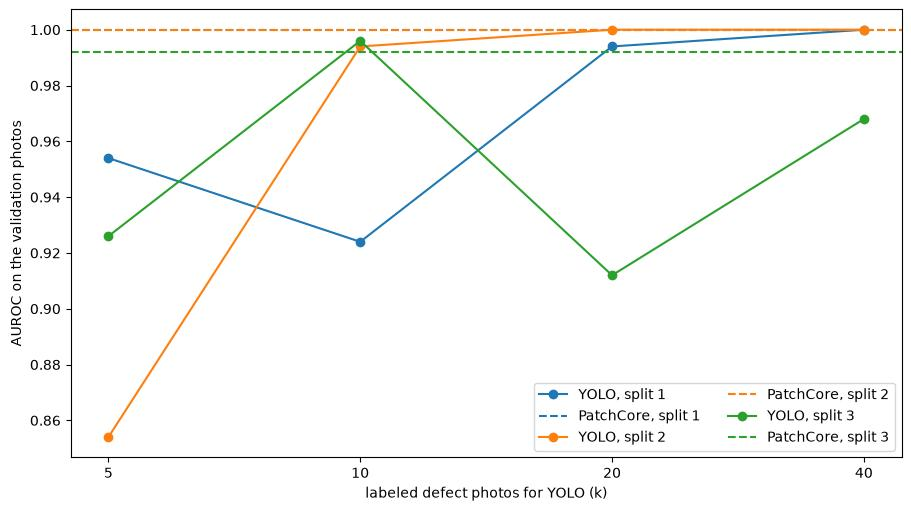

,split 1,split 2,split 3,mean
model,,,,
PatchCore,1.000,1.000,0.992,0.997
YOLO k = 5,0.954,0.854,0.926,0.911
YOLO k = 10,0.924,0.994,0.996,0.971
YOLO k = 20,0.994,1.000,0.912,0.969
YOLO k = 40,1.000,1.000,0.968,0.989


In [14]:
auroc_rows = []
for s in SPLITS:
    patchcore = pd.read_csv(os.path.join(PATCHCORE_DIR, f"split_{s}_scores.csv"))
    patchcore_val = patchcore[patchcore["part"] == "val"]
    auroc_rows.append({"model": "PatchCore", "split": s,
                       "AUROC": roc_auc_score(patchcore_val["is_defect"], patchcore_val["score"])})
    for k in K_VALUES:
        val = scores[s][(scores[s]["part"] == "val") & (scores[s]["k"] == k)]
        auroc_rows.append({"model": f"YOLO k = {k}", "split": s, "AUROC": roc_auc_score(val["is_defect"], val["score"])})
auroc = pd.DataFrame(auroc_rows).pivot(index="model", columns="split", values="AUROC")
auroc = auroc.loc[["PatchCore"] + [f"YOLO k = {k}" for k in K_VALUES]]
auroc.columns = [f"split {s}" for s in auroc.columns]
auroc["mean"] = auroc.mean(axis=1)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for s, color in zip(SPLITS, ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(K_VALUES, [auroc.loc[f"YOLO k = {k}", f"split {s}"] for k in K_VALUES], marker="o", color=color,
            label=f"YOLO, split {s}")
    ax.axhline(auroc.loc["PatchCore", f"split {s}"], color=color, linestyle="--", label=f"PatchCore, split {s}")
ax.set_xscale("log", base=2)
ax.set_xticks(K_VALUES, [str(k) for k in K_VALUES])
ax.set_xlabel("labeled defect photos for YOLO (k)")
ax.set_ylabel("AUROC on the validation photos")
ax.legend(ncol=2)
plt.show()
auroc.round(3)

> **What we see:**
>
> - **PatchCore** ranks the validation photos almost perfectly without any labeled defect photo: 1.000, 1.000 and 0.992 (mean 0.997). In the figure, its lines of split 1 and split 2 are both at 1.000, so the blue dashed line is hidden under the orange one.
> - **YOLO** gets better with more labeled defect photos, but not in a straight line. Its mean AUROC is 0.911 at k = 5, 0.971 at k = 10, 0.969 at k = 20 and 0.989 at k = 40.
> - The splits differ a lot for the same k. At k = 5, split 2 is at 0.854 and split 1 at 0.954. Split 3 reaches 0.996 at k = 10 and drops to 0.912 at k = 20. Each split has only 10 defect validation photos, and every defect photo is compared with all 50 normal photos, so one defect photo that YOLO misses pulls the AUROC down a lot.
> - YOLO reaches PatchCore's dashed line in split 1 at k = 40, in split 2 from k = 20, and in split 3 only at k = 10 (0.996, above PatchCore's 0.992). On average, even with 40 labeled defect photos, YOLO stays just below PatchCore.
>
> This is a first look, with 10 defect photos per split. Step 5 checks it on the 150 test photos per split, with the PASS/REJECT limit.

### Scores of Normal and Defect Validation Photos

> For split 1, one histogram per k: the YOLO scores of the 50 normal (green) and 10 defect (red) validation photos. A good model gives the defect photos high scores and the normal photos low scores, with little overlap.
>
> - `example`: the validation rows of split 1 (all 4 k values). The next figures use it too.
> - Many scores are tiny, so the score axis is logarithmic (`set_xscale("log")`): every step to the right is 10 times more, as in the loss figure of notebook 4.2. That way the order of the tiny scores is visible too, and this order is what the AUROC and the PASS/REJECT limit of step 5 use.
> - `lowest_power`: the axis starts at the power of 10 just below the smallest score in `example` (for example 0.0001 if the smallest score is 0.00035). `bins`: 4 bars per step of 10.

k = 5: normal scores 4.81e-05 to 0.0391 | defect scores 0.000461 to 0.966
k = 10: normal scores 0.000137 to 0.729 | defect scores 0.000569 to 0.957
k = 20: normal scores 0.000105 to 0.701 | defect scores 0.136 to 0.951
k = 40: normal scores 9.15e-05 to 0.102 | defect scores 0.565 to 0.928


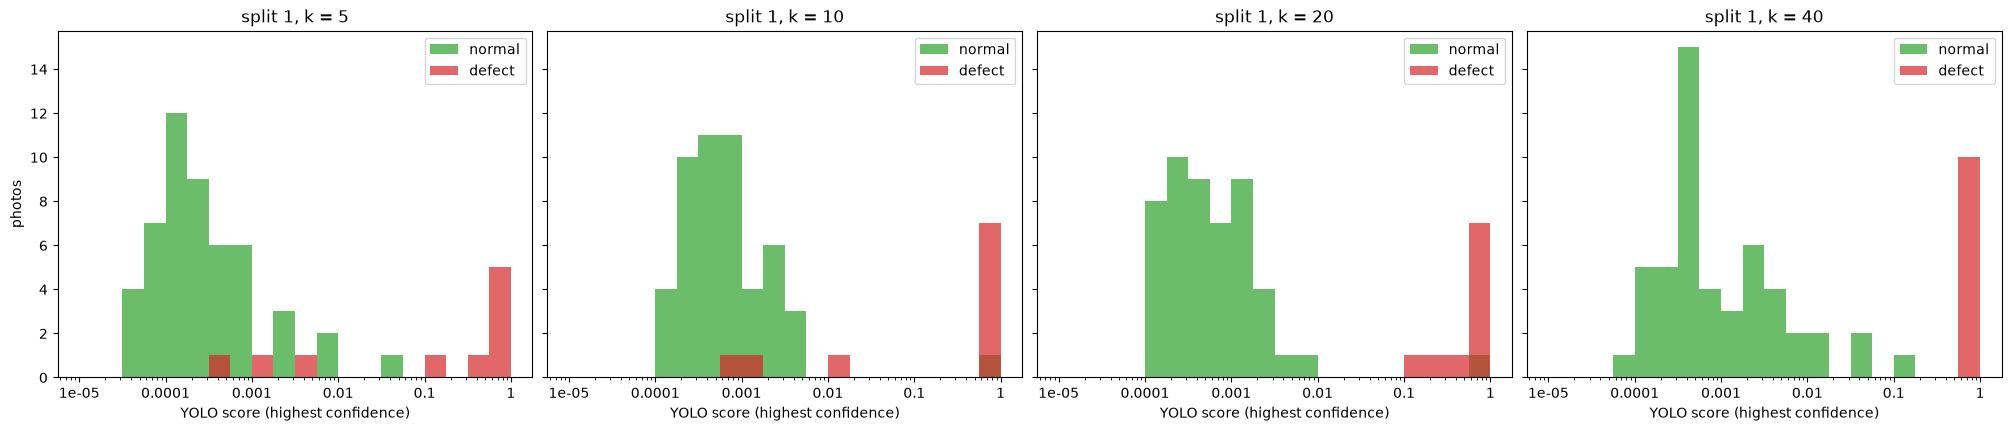

In [15]:
example = scores[EXAMPLE_SPLIT][scores[EXAMPLE_SPLIT]["part"] == "val"]
lowest_power = int(np.floor(np.log10(example.loc[example["score"] > 0, "score"].min())))
bins = np.logspace(lowest_power, 0, 4 * -lowest_power + 1)
ticks = 10.0 ** np.arange(lowest_power, 1)

fig, axes = plt.subplots(1, len(K_VALUES), figsize=(20, 4.2), sharey=True, layout="constrained")
for ax, k in zip(axes, K_VALUES):
    val = example[example["k"] == k]
    ax.hist(val.loc[~val["is_defect"], "score"], bins=bins, color="tab:green", alpha=0.7, label="normal")
    ax.hist(val.loc[val["is_defect"], "score"], bins=bins, color="tab:red", alpha=0.7, label="defect")
    ax.set_xscale("log")
    ax.set_xticks(ticks, [f"{tick:g}" for tick in ticks])
    ax.set_title(f"split {EXAMPLE_SPLIT}, k = {k}")
    ax.set_xlabel("YOLO score (highest confidence)")
    ax.legend()
    print(f"k = {k}: normal scores {val.loc[~val['is_defect'], 'score'].min():.3g} to {val.loc[~val['is_defect'], 'score'].max():.3g} | "
          f"defect scores {val.loc[val['is_defect'], 'score'].min():.3g} to {val.loc[val['is_defect'], 'score'].max():.3g}")
axes[0].set_ylabel("photos")
plt.show()

> **What we see** (split 1; a dark bar means green and red in the same place):
>
> - **Normal photos** (green) get tiny scores from every model: most green bars lie between the ticks 0.0001 and 0.01.
> - **k = 5:** most defect photos are far to the right (up to 0.966), but some red bars stand among the green ones. The lowest defect score, 0.000461, is lower than many normal scores (4.81e-05 to 0.0391): for this model, that defect photo looks like good gum.
> - **k = 10 and k = 20:** one normal photo gets a high score (0.729 and 0.701, the dark part of the right-most bar). YOLO is quite sure about a defect that is not there. At k = 10, some defect photos also still score like good gum (the lowest is 0.000569). Together, this puts split 1's AUROC at k = 10 (0.924) below k = 5 (0.954). At k = 20, every defect photo scores at least 0.136.
> - **k = 40:** the two colours are fully apart: normal photos at most 0.102, defect photos at least 0.565. That is why YOLO's AUROC of split 1 is 1.000 at k = 40.

### Where YOLO Looks: Defect Photos

> The `EXAMPLE_PHOTOS` defect validation photos of split 1 that the k = 5 model scores lowest: the hardest ones for it. Top row: the k = 5 model, bottom row: the k = 40 model. White dashed: the true boxes. Red: the most confident YOLO box, the one that gives the score, with its confidence.

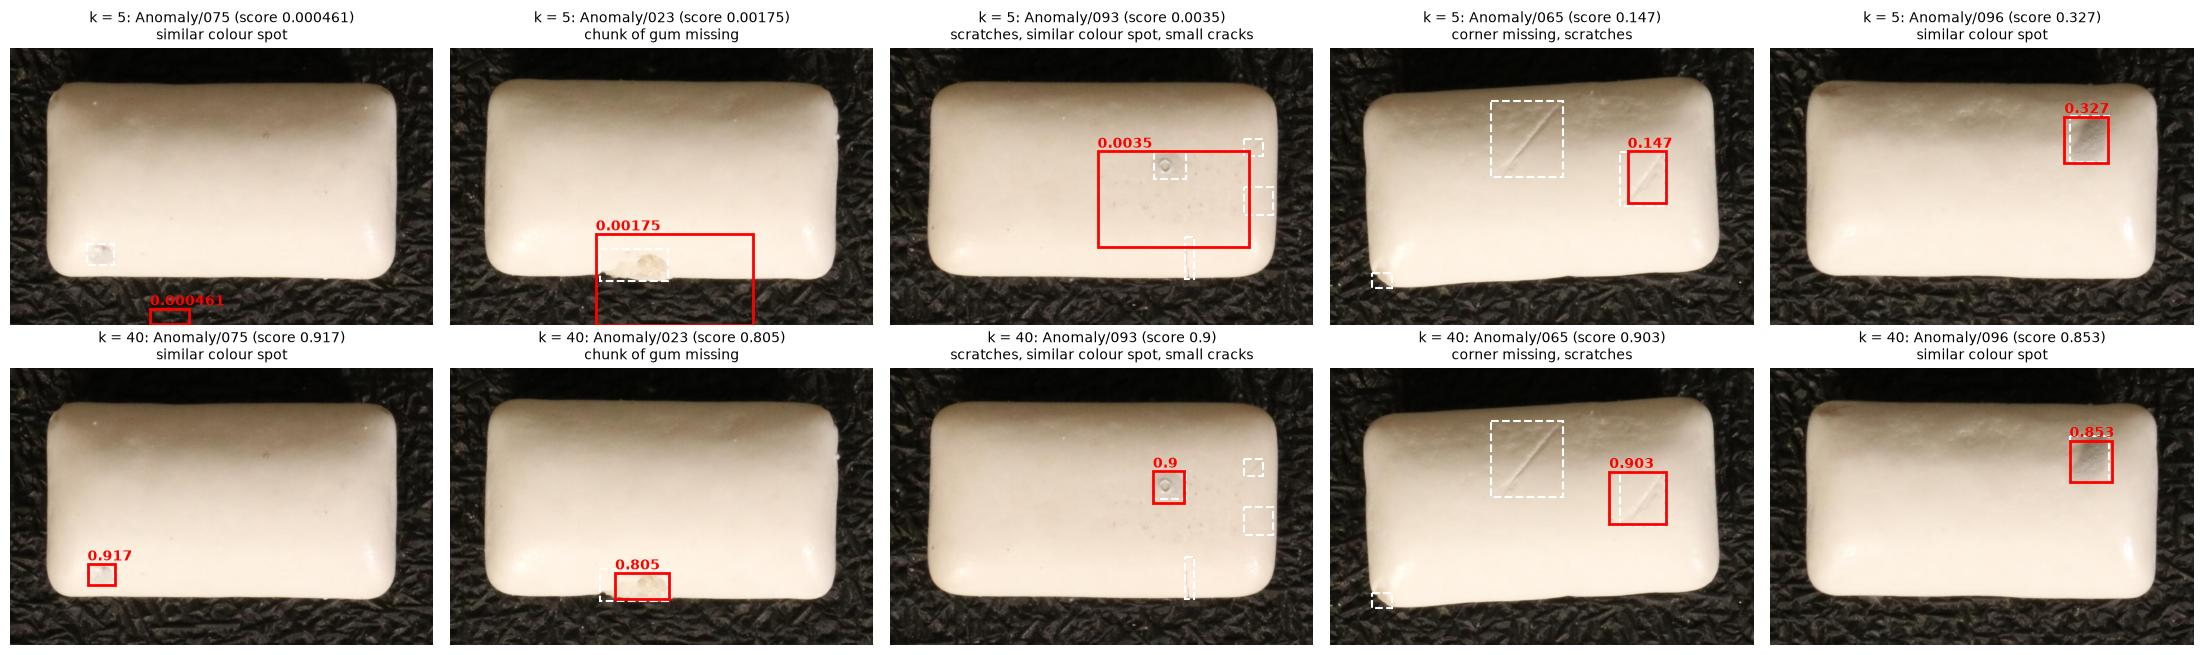

In [16]:
hardest = (example[example["is_defect"] & (example["k"] == K_VALUES[0])]
           .sort_values("score").head(EXAMPLE_PHOTOS)["crop_image"].tolist())

fig, axes = plt.subplots(2, EXAMPLE_PHOTOS, figsize=(22, 6.4), layout="constrained")
for row, k in enumerate([K_VALUES[0], K_VALUES[-1]]):
    for ax, crop_image in zip(axes[row], hardest):
        photo = example[(example["k"] == k) & (example["crop_image"] == crop_image)].iloc[0]
        crop = Image.open(full_path(CROP_DIR, crop_image)).convert("RGB")
        best_box = photo[["best_left", "best_top", "best_right", "best_bottom"]].to_numpy(dtype=float)
        show_boxes(ax, crop, true_boxes(crop_image, CROP_SIZE), best_box, photo["score"])
        ax.set_title(f"k = {k}: {short_name(crop_image)} (score {photo['score']:.3g})\n"
                     f"{photo['defect_types'].replace(',', ', ')}", fontsize=10)
plt.show()

> **What we see:**
>
> - **k = 5 (top row):** these 5 defect photos get only 0.000461 to 0.327.
>   - `Anomaly/075`: the best box lies on the mat below the gum, not on the spot. This model did not see the defect at all.
>   - `Anomaly/023` and `Anomaly/093`: a big box around the area of the defect, but the model is far from sure (0.00175 and 0.0035).
>   - `Anomaly/065` and `Anomaly/096`: the box lies on a real defect, but with a low confidence (0.147 and 0.327).
> - **k = 40 (bottom row):** on the same photos, every red box lies on a white box, with confidences from 0.805 to 0.917. With 40 labeled defect photos, YOLO has learned what these defects look like.
> - Only the most confident box is drawn. Some white boxes have no red box here, such as the long scratch of `Anomaly/065` and the small cracks of `Anomaly/093`. YOLO may still have a less confident box on them: the boxes files keep up to 20 boxes per photo.

### Where YOLO Looks: Normal Photos

> The 3 normal validation photos of split 1 with the highest score of the k = 5 model, with the boxes of the k = 5 model (top) and the k = 40 model (bottom). Normal photos have no true boxes, so every red box is a false lead; a low confidence means YOLO is not sure about it.

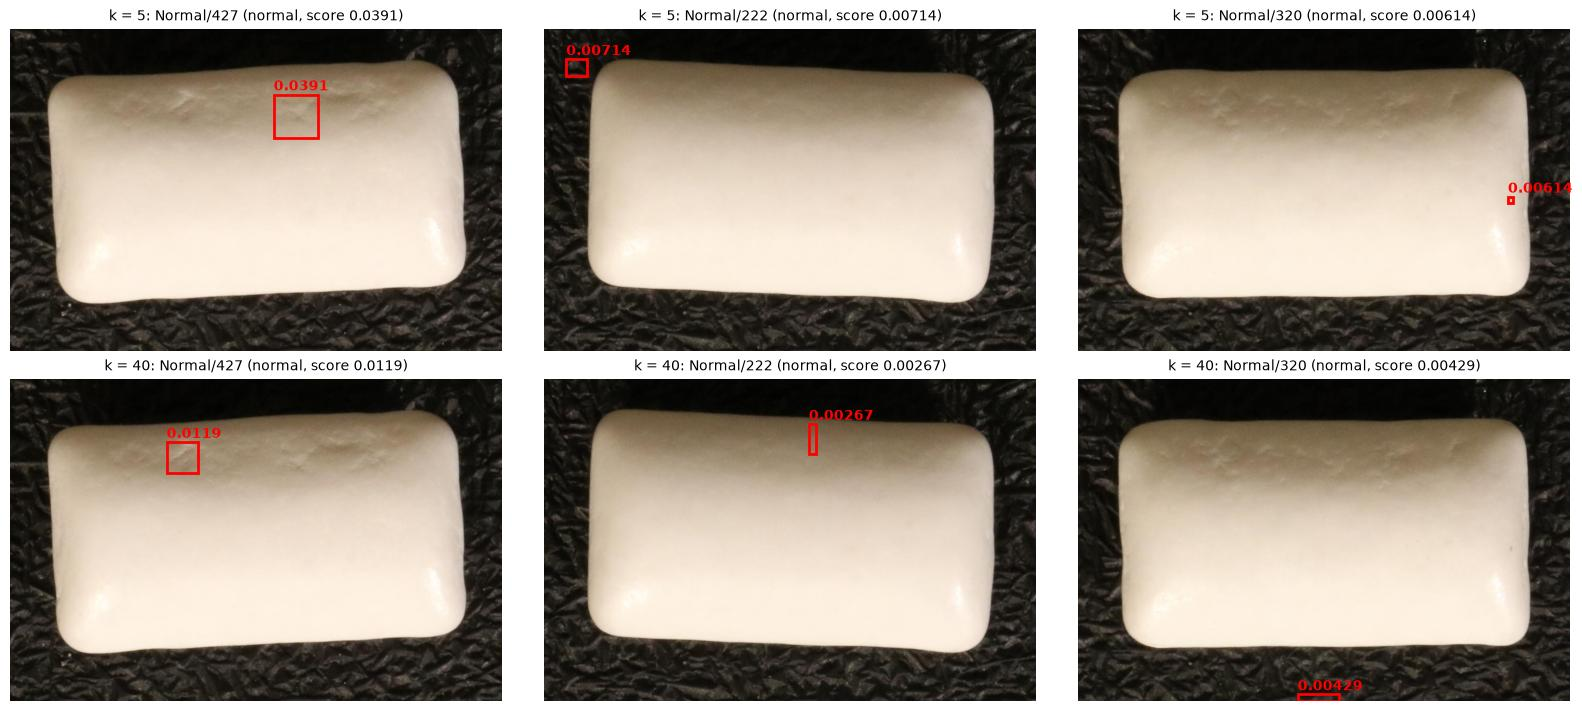

In [17]:
suspicious = (example[~example["is_defect"] & (example["k"] == K_VALUES[0])]
              .sort_values("score", ascending=False).head(3)["crop_image"].tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 7), layout="constrained")
for row, k in enumerate([K_VALUES[0], K_VALUES[-1]]):
    for ax, crop_image in zip(axes[row], suspicious):
        photo = example[(example["k"] == k) & (example["crop_image"] == crop_image)].iloc[0]
        crop = Image.open(full_path(CROP_DIR, crop_image)).convert("RGB")
        best_box = photo[["best_left", "best_top", "best_right", "best_bottom"]].to_numpy(dtype=float)
        show_boxes(ax, crop, [], best_box, photo["score"])
        ax.set_title(f"k = {k}: {short_name(crop_image)} (normal, score {photo['score']:.3g})", fontsize=10)
plt.show()

> **What we see:**
>
> - The 3 normal photos that the k = 5 model finds most suspicious still get very low scores: 0.0391, 0.00714 and 0.00614. Its boxes lie on small folds at the top of the gum (`Normal/427`), on the mat (`Normal/222`) and at the edge of the gum (`Normal/320`). YOLO is not sure about anything here.
> - The k = 40 model is even less sure on the same photos: 0.0119, 0.00267 and 0.00429.
> - These are only the most suspicious photos of the k = 5 model. The k = 10 and k = 20 models each gave one normal photo a high score (0.729 and 0.701, see the histograms). Step 5 looks at such false alarms on the test photos.

## Summary

> **What this notebook did**
>
> - Let each of the 12 YOLO models (`last.pt` of notebook 4.2) predict the validation and test photos of its split.
> - Gave every photo one score: the highest confidence of YOLO's boxes, with no lower limit, so that photos do not share the score 0. This is the same kind of score as PatchCore's: one number per photo, higher means more likely a defect.
> - Saved the scores and boxes (`results/yolo/`), and read them back to check them.
> - Looked only at the validation photos: AUROC per k next to PatchCore, score histograms, and boxes on the hardest defect photos and the most suspicious normal photos.
>
> **What we found (validation photos only)**
>
> - Without a lower limit, every photo has its own score. With the usual limit of 0.001, 146 to 160 of the 240 validation scores per split would have been 0.
> - Mean AUROC of the 3 splits: PatchCore 0.997, without labeled defect photos. YOLO 0.911 (k = 5), 0.971 (k = 10), 0.969 (k = 20) and 0.989 (k = 40).
> - YOLO gets better with more labeled defect photos, but not in a straight line, and the splits differ a lot. With k = 5 it misses some defects completely; with k = 40 it finds the same defects with high confidence.
>
> **Data leakage:** the models only learned from train photos (notebook 4.2), and the test scores were saved without being looked at.
>
> **Next:** step 5, the comparison of PatchCore and YOLO on the test photos.